# rand_schematics.py

*Generated from `rand_schematics.py` by `tools/build_notebooks.py`. Edit the script, then rebuild.*

```text
rand_schematics.py - figures of the random-orientation SIM set-up.

Rebuilds the geometry with the decks' maths (lattice + origin shift -> rotate by
Rz(alpha) Rx(beta) Rz(gamma) -> keep r <= R, z <= 0; unrelaxed).  Euler angles
come from the decks' random stream (LAMMPS python module if installed, else
numpy draws, flagged in the figure).

Outputs:
  rand_steps_WC.png / _slide.png   (a) crystal ball, (b) rotation, (c) hemisphere cut
  rand_crosssection_WC.png         layers and impact geometry of the R = 50 A hemisphere
  rand_orientations.png / _vertical.png   surface normals on the IPF (W cubic, WC hexagonal)
  rand_example_surfaces.png        top views of three random WC surfaces

    python rand_schematics.py [--n 50] [--out .]
```

In [ ]:
# settings (the same as the script's command line)
import os, sys
SCRIPT = 'rand_schematics.py'
NB_OUT = "nb_figs"
ARGS = ["--n", "50", "--out", NB_OUT]
sys.argv = [SCRIPT] + ARGS
__file__ = os.path.abspath(SCRIPT)

In [2]:
import argparse
import os
import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, FancyArrowPatch

In [3]:
# ---- geometry (match the decks) -----------------------------------------
A_WC, C_WC = 2.92949147531862, 2.82420965326672
A_W = 3.165
R_PROD = 50.0
D_FIX, D_THM = 3.0, 10.0
H_LAUNCH, D_CAP, D_CUTW, D_CUTC = 8.0, 18.0, 3.8, 3.0
L_IMP_WC = 11.7
ANG = 30.0

COL_W, COL_C, COL_HE = "#8c8c8c", "#3b6fd6", "#f2b705"
COL_NVE, COL_NVT, COL_FIX, COL_IMP = "#4f7fd9", "#3aa655", "#d64545", "#ff8200"


# ---- the decks' random stream -------------------------------------------
def euler_from_lammps(s, material):
    """alpha, beta, gamma, ox, oy, oz exactly as in_rand_<material>.step1 draws them."""
    import lammps
    l = lammps.lammps(cmdargs=["-log", "none", "-screen", "none"])
    l.command(f"variable seed0 equal 1000003*{s}+17")
    for k in ("alpha", "beta", "gamma", "ox", "oy", "oz"):
        l.command(f"variable u_{k} equal $(random(0.0,1.0,v_seed0))")
    u = {k: l.extract_variable(f"u_{k}") for k in ("alpha", "beta", "gamma", "ox", "oy", "oz")}
    l.close()
    return (360.0 * u["alpha"], np.degrees(np.arccos(2.0 * u["beta"] - 1.0)), 360.0 * u["gamma"],
            0.999 * u["ox"], 0.999 * u["oy"], 0.999 * u["oz"])


def euler_numpy(s):
    rng = np.random.default_rng(1000003 * s + 17)
    u = rng.random(6)
    return (360 * u[0], np.degrees(np.arccos(2 * u[1] - 1)), 360 * u[2], *(0.999 * u[3:]))


def get_angles(s, material):
    try:
        return euler_from_lammps(s, material), True
    except Exception:
        return euler_numpy(s), False

In [4]:
def rot_z(deg):
    t = np.radians(deg); c, s = np.cos(t), np.sin(t)
    return np.array([[c, -s, 0], [s, c, 0], [0, 0, 1]])


def rot_x(deg):
    t = np.radians(deg); c, s = np.cos(t), np.sin(t)
    return np.array([[1, 0, 0], [0, c, -s], [0, s, c]])


def rotation(alpha, beta, gamma):
    """R = Rz(alpha) Rx(beta) Rz(gamma): the three displace_atoms rotate calls, gamma first."""
    return rot_z(alpha) @ rot_x(beta) @ rot_z(gamma)


def ball_WC(radius, origin):
    a, c = A_WC, C_WC
    a1, a2, a3 = np.array([a, 0, 0]), np.array([0, np.sqrt(3) * a, 0]), np.array([0, 0, c])
    basis = np.array([[0, 0, 0], [0.5, 0.5, 0], [0, 2 / 3, 0.5], [0.5, 1 / 6, 0.5]])
    types = np.array([1, 1, 2, 2])
    n = int(np.ceil(radius / min(a, c))) + 2
    pts, typ = [], []
    for i in range(-n, n + 1):
        for j in range(-n // 1, n + 1):
            for k in range(-n, n + 1):
                for b, t in zip(basis, types):
                    f = np.array([i, j, k]) + b + np.asarray(origin)
                    pts.append(f[0] * a1 + f[1] * a2 + f[2] * a3)
                    typ.append(t)
    pts, typ = np.array(pts), np.array(typ)
    keep = np.linalg.norm(pts, axis=1) <= radius
    return pts[keep], typ[keep]


def hemisphere(pts, typ, R):
    keep = (np.linalg.norm(pts, axis=1) <= R) & (pts[:, 2] <= 0.0)
    return pts[keep], typ[keep]


# ---- figure 1: the four steps --------------------------------------------
def fig_steps(out, s=2, slide=False):
    """slide=True: compact 9 x 3.4 in version with larger text and no footnote (rand_steps_WC_slide.png)."""
    (al, be, ga, ox, oy, oz), exact = get_angles(s, "WC")
    Rm = rotation(al, be, ga)
    Rd = 16.0                                   # small ball so atoms are visible
    p0, t0 = ball_WC(Rd + 1.5, (ox, oy, oz))
    p1 = p0 @ Rm.T
    p2, t2 = hemisphere(p1, t0, Rd)

    fig = plt.figure(figsize=(9, 3.4) if slide else (13, 4.8))
    titles = ["(a) WC ball in the crystal frame", "(b) rotate by Rz(α) Rx(β) Rz(γ)",
              "(c) keep r ≤ R and z ≤ 0"]
    fs_t, fs_l = (12, 9) if slide else (11, 8)
    sets = [(p0, t0, np.eye(3)), (p1, t0, Rm), (p2, t2, Rm)]
    for k, (p, t, Rax) in enumerate(sets):
        ax = fig.add_subplot(1, 3, k + 1, projection="3d")
        for tt, col, sz in ((1, COL_W, 9), (2, COL_C, 5)):
            m = t == tt
            ax.scatter(p[m, 0], p[m, 1], p[m, 2], s=sz, c=col, depthshade=True, linewidths=0)
        # crystal axes a, m, c (rotated with the crystal)
        for vec, lab, col in ((np.array([1, 0, 0]), "a [2-1-10]", "#d62728"),
                              (np.array([0, 1, 0]), "m [01-10]", "#2ca02c"),
                              (np.array([0, 0, 1]), "c [0001]", "#1f1f9f")):
            v = Rax @ vec * (Rd + 6)
            ax.quiver(0, 0, 0, *v, color=col, linewidth=2, arrow_length_ratio=0.12)
            ax.text(*(v * 1.12), lab, color=col, fontsize=fs_l)
        ax.set_title(titles[k], fontsize=fs_t)
        lim = Rd + 6
        ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim); ax.set_zlim(-lim, lim)
        ax.set_box_aspect((1, 1, 1))
        ax.view_init(elev=18, azim=-60)
        ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([])
        ax.set_xlabel(""); ax.set_ylabel(""); ax.set_zlabel("")
    if not slide:
        fig.text(0.02, 0.02, "Surface %d: α=%.0f°, β=%.0f°, γ=%.0f°; drawn with R = %.0f Å for clarity "
                 "(production R = %.0f Å).  W grey, C blue.%s"
                 % (s, al, be, ga, Rd, R_PROD, "" if exact else "  [angles from numpy, not the LAMMPS stream]"),
                 fontsize=9, color="#555555")
    fig.tight_layout(rect=(0, 0 if slide else 0.05, 1, 1))
    path = os.path.join(out, "rand_steps_WC%s.png" % ("_slide" if slide else ""))
    fig.savefig(path, dpi=200)
    plt.close(fig)
    print("wrote", path)

In [5]:
def fig_crosssection(out, s=2):
    (al, be, ga, ox, oy, oz), exact = get_angles(s, "WC")
    Rm = rotation(al, be, ga)
    fig, ax = plt.subplots(figsize=(11, 6.2))
    pP, tP = ball_WC(R_PROD + 1.0, (ox, oy, oz))
    pP = pP @ Rm.T
    pP, tP = hemisphere(pP, tP, R_PROD)
    sl = np.abs(pP[:, 1]) < 1.6
    r = np.linalg.norm(pP[sl], axis=1)
    lay = np.where(r > R_PROD - D_FIX, COL_FIX, np.where(r > R_PROD - D_THM, COL_NVT, COL_NVE))
    ax.scatter(pP[sl, 0], pP[sl, 2], s=5, c=lay, linewidths=0)
    ax.add_patch(Rectangle((-L_IMP_WC / 2, 0.3), L_IMP_WC, 1.0, color=COL_IMP))
    th = np.radians(ANG)
    x0, z0 = -H_LAUNCH * np.tan(th), H_LAUNCH
    ax.add_patch(FancyArrowPatch((x0, z0), (0, 0.8), arrowstyle="-|>", mutation_scale=14,
                                 color=COL_HE, lw=2.2))
    ax.plot([x0], [z0], "o", color=COL_HE, ms=8, mec="k", mew=0.5)
    ax.annotate("He launch point\n%g\u00b0 off normal, random azimuth" % ANG, xy=(x0, z0),
                xytext=(-62, 12), fontsize=10, color="#7a5d00",
                arrowprops=dict(arrowstyle="-", color="#7a5d00", lw=0.8))
    ax.annotate("impact square %.1f \u00c5 (4a)" % L_IMP_WC, xy=(L_IMP_WC / 2, 0.8),
                xytext=(16, 11.5), fontsize=10, color=COL_IMP,
                arrowprops=dict(arrowstyle="-", color=COL_IMP, lw=0.8))
    for zz, lab, ls in ((D_CAP, "capture plane  z$_s$ + %g \u00c5  (count + delete)" % D_CAP, "--"),
                        (H_LAUNCH, "launch height  z$_s$ + %g \u00c5" % H_LAUNCH, (0, (1, 3))),
                        (D_CUTW, "end-of-impact cut  z$_s$ + %g \u00c5 (W), %g \u00c5 (C)" % (D_CUTW, D_CUTC), ":")):
        ax.plot([-22, R_PROD + 2], [zz, zz], color="#555555", ls=ls, lw=1)
        ax.text(R_PROD + 4, zz, lab, fontsize=9.5, va="center", color="#444444")
    ax.text(0, -22, "NVE core\n(r < R \u2212 %g \u00c5)" % D_THM, color="#1d3f8f", fontsize=11, ha="center",
            va="center", weight="bold", bbox=dict(boxstyle="round,pad=0.3", fc="white", ec=COL_NVE, alpha=0.9))
    ax.annotate("thermostat shell (%g \u00c5, NVT)" % (D_THM - D_FIX), xy=(-30, -36), xytext=(-60, -62),
                color=COL_NVT, fontsize=10, arrowprops=dict(arrowstyle="-", color=COL_NVT, lw=0.8))
    ax.annotate("fixed shell (%g \u00c5)" % D_FIX, xy=(30, -39.5), xytext=(32, -62),
                color=COL_FIX, fontsize=10, arrowprops=dict(arrowstyle="-", color=COL_FIX, lw=0.8))
    ax.text(R_PROD + 4, -8, "flat face z = 0 = the random\nsurface; z$_s$ = top atom within\n8 \u00c5 of the axis",
            fontsize=9.5, color="#444444", va="center")
    ax.set_aspect("equal")
    ax.set_xlim(-R_PROD - 14, R_PROD + 62)
    ax.set_ylim(-R_PROD - 18, D_CAP + 6)
    ax.set_xlabel("x (\u00c5)"); ax.set_ylabel("z (\u00c5)")
    ax.set_title("Random-orientation hemisphere, R = %g \u00c5 (slice |y| < 1.6 \u00c5): layers and impact geometry"
                 % R_PROD, fontsize=12)
    for sp in ("top", "right"):
        ax.spines[sp].set_visible(False)
    fig.tight_layout()
    path = os.path.join(out, "rand_crosssection_WC.png")
    fig.savefig(path, dpi=200)
    plt.close(fig)
    print("wrote", path)

In [6]:
# ---- figure 2: orientation sampling --------------------------------------
def normal(beta, gamma):
    b, g = np.radians(beta), np.radians(gamma)
    return np.array([np.sin(b) * np.sin(g), np.sin(b) * np.cos(g), np.cos(b)])


def ipf_cubic(n):
    v = np.sort(np.abs(n))              # x <= y <= z
    return v[0] / (1 + v[2]), v[1] / (1 + v[2])


def ipf_hex(n):
    # crystal frame: x = a [2-1-10], y = m [01-10], z = c [0001]
    th = np.arccos(min(1.0, abs(n[2])))
    ph = np.degrees(np.arctan2(n[1], n[0])) % 60.0
    if ph > 30.0:
        ph = 60.0 - ph
    r = np.tan(th / 2)
    return r * np.cos(np.radians(ph)), r * np.sin(np.radians(ph))


def fig_orientations(out, n_surf, vertical=False):
    fig, axs = plt.subplots(2, 1, figsize=(5.6, 8.4)) if vertical else plt.subplots(1, 2, figsize=(11, 4.8))
    exact_all = True
    # W, cubic standard triangle 001-011-111
    ax = axs[0]
    t = np.linspace(0, 1, 100)
    arc = np.array([ipf_cubic(np.array([u, 1.0, 1.0]) / np.linalg.norm([u, 1.0, 1.0])) for u in t])
    ax.plot([0, 0], [0, np.sqrt(2) - 1], "k-", lw=1)
    ax.plot([0, ipf_cubic(np.ones(3) / np.sqrt(3))[0]], [0, ipf_cubic(np.ones(3) / np.sqrt(3))[1]], "k-", lw=1)
    ax.plot(arc[:, 0], arc[:, 1], "k-", lw=1)
    pts = []
    for s in range(1, n_surf + 1):
        (al, be, ga, *_), ex = get_angles(s, "W")
        exact_all &= ex
        pts.append(ipf_cubic(normal(be, ga)))
    pts = np.array(pts)
    ax.scatter(pts[:, 0], pts[:, 1], s=22, c=COL_W, edgecolors="k", linewidths=0.4, label="random surfaces", zorder=3)
    for lab, v in (("(001)", [0, 0, 1]), ("(011)", [0, 1, 1]), ("(111)", [1, 1, 1])):
        x, y = ipf_cubic(np.array(v) / np.linalg.norm(v))
        ax.plot(x, y, "s", color=COL_IMP, ms=9, zorder=4)
        ax.text(x + 0.015, y - 0.005 if lab == "(001)" else y + 0.012, lab, fontsize=10)
    ax.set_title("W: surface normals in the crystal frame (cubic IPF)", fontsize=11)
    ax.set_aspect("equal"); ax.axis("off")
    ax.legend(loc="center right", fontsize=9, frameon=False)

    # WC, hexagonal standard triangle 0001 - 2-1-10 - 10-10
    ax = axs[1]
    tt = np.radians(np.linspace(0, 30, 100))
    ax.plot([0, 1], [0, 0], "k-", lw=1)
    ax.plot([0, np.cos(np.radians(30))], [0, np.sin(np.radians(30))], "k-", lw=1)
    ax.plot(np.cos(tt), np.sin(tt), "k-", lw=1)
    pts = []
    for s in range(1, n_surf + 1):
        (al, be, ga, *_), ex = get_angles(s, "WC")
        exact_all &= ex
        pts.append(ipf_hex(normal(be, ga)))
    pts = np.array(pts)
    ax.scatter(pts[:, 0], pts[:, 1], s=22, c=COL_C, edgecolors="k", linewidths=0.4, label="random surfaces", zorder=3)
    for lab, (x, y), off in (("basal (0001)", (0, 0), (-0.02, -0.07)), ("a-plane (11-20)", (1, 0), (0.03, -0.07)),
                             ("prism (10-10)", (np.cos(np.radians(30)), np.sin(np.radians(30))), (0.04, 0.0))):
        ax.plot(x, y, "s", color=COL_IMP, ms=9, zorder=4)
        ax.text(x + off[0], y + off[1], lab, fontsize=10)
    ax.set_title("WC: surface normals in the crystal frame (hexagonal IPF)", fontsize=11)
    ax.set_aspect("equal"); ax.axis("off")
    ax.set_xlim(-0.08, 1.35); ax.set_ylim(-0.12, 0.62)
    ax.legend(loc="upper left", fontsize=9, frameon=False)
    if vertical:
        axs[0].set_title("W: surface normals (cubic IPF)", fontsize=12)
        axs[1].set_title("WC: surface normals (hexagonal IPF)", fontsize=12)
        fig.text(0.02, 0.01, "%d surfaces each; orange = low-index references%s"
                 % (n_surf, "" if exact_all else "  [numpy draws]"), fontsize=9, color="#555555")
    else:
        fig.text(0.01, 0.01, "%d surfaces each, Euler angles with cosβ uniform (uniform over all orientations); "
                 "orange squares = low-index references%s" % (n_surf, "" if exact_all else "  [numpy draws]"),
                 fontsize=9, color="#555555")
    fig.tight_layout(rect=(0, 0.04, 1, 1))
    path = os.path.join(out, "rand_orientations%s.png" % ("_vertical" if vertical else ""))
    fig.savefig(path, dpi=200)
    plt.close(fig)
    print("wrote", path)

In [7]:
# ---- figure 3: what random WC surfaces look like --------------------------
def fig_examples(out, ids=(1, 2, 3)):
    fig, axs = plt.subplots(1, len(ids), figsize=(4.6 * len(ids), 4.6))
    for ax, s in zip(axs, ids):
        (al, be, ga, ox, oy, oz), ex = get_angles(s, "WC")
        Rm = rotation(al, be, ga)
        p, t = ball_WC(R_PROD + 1.0, (ox, oy, oz))
        p = p @ Rm.T
        p, t = hemisphere(p, t, R_PROD)
        top = p[:, 2] > -4.5
        sc = ax.scatter(p[top, 0], p[top, 1], c=p[top, 2], s=np.where(t[top] == 1, 9, 4),
                        cmap="viridis", vmin=-4.5, vmax=0, linewidths=0)
        ax.add_patch(Rectangle((-L_IMP_WC / 2, -L_IMP_WC / 2), L_IMP_WC, L_IMP_WC, fill=False,
                               ec=COL_IMP, lw=2))
        n = normal(be, ga)
        fC = np.mean(t[p[:, 2] > -3.0] == 2)
        ax.set_title("surface %d: n = (%.2f, %.2f, %.2f)\ntop-3 Å C fraction %.2f"
                     % (s, n[0], n[1], n[2], fC), fontsize=10)
        ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
    cb = fig.colorbar(sc, ax=axs, shrink=0.8, pad=0.01)
    cb.set_label("height below the cut (Å)")
    fig.suptitle("Random WC surfaces are stepped and mixed-termination (top view, unrelaxed; orange = impact square)",
                 fontsize=11)
    path = os.path.join(out, "rand_example_surfaces.png")
    fig.savefig(path, dpi=200, bbox_inches="tight")
    plt.close(fig)
    print("wrote", path)

In [8]:
if __name__ == "__main__":
    ap = argparse.ArgumentParser()
    ap.add_argument("--n", type=int, default=50, help="number of surfaces in the IPF figure")
    ap.add_argument("--out", default=".")
    a = ap.parse_args()
    os.makedirs(a.out, exist_ok=True)
    fig_steps(a.out)
    fig_steps(a.out, slide=True)
    fig_crosssection(a.out)
    fig_orientations(a.out, a.n)
    fig_orientations(a.out, a.n, vertical=True)
    fig_examples(a.out)

wrote nb_figs/rand_steps_WC.png


wrote nb_figs/rand_steps_WC_slide.png


wrote nb_figs/rand_crosssection_WC.png


wrote nb_figs/rand_orientations.png


wrote nb_figs/rand_orientations_vertical.png


wrote nb_figs/rand_example_surfaces.png


## Outputs

In [9]:
# display helper: embeds the outputs in this notebook (big GIFs and PNGs are shrunk first)
import glob, io
from IPython.display import Image, display
from PIL import Image as PILImage

def _shrink_png(path, width=1200):
    im = PILImage.open(path)
    if im.width > width:
        im = im.resize((width, round(im.height * width / im.width)), PILImage.LANCZOS)
    buf = io.BytesIO()
    im.save(buf, "PNG", optimize=True)
    return buf.getvalue()

def _shrink_gif(path, max_kb):
    src = PILImage.open(path)
    frames, durations = [], []
    try:
        while True:
            frames.append(src.convert("RGB"))
            durations.append(src.info.get("duration", 80))
            src.seek(src.tell() + 1)
    except EOFError:
        pass
    w0 = min(frames[0].width, 640)
    # smaller frames first; drop frames only if that is not enough
    for step, width in [(1, w0), (1, int(w0 * 0.8)), (1, int(w0 * 0.65)), (2, int(w0 * 0.8)),
                        (2, int(w0 * 0.65)), (4, int(w0 * 0.65)), (8, int(w0 * 0.5))]:
        sel = frames[::step]
        size = (width, round(frames[0].height * width / frames[0].width))
        sel = [f.resize(size, PILImage.LANCZOS).quantize(colors=128) for f in sel]
        buf = io.BytesIO()
        sel[0].save(buf, "GIF", save_all=True, append_images=sel[1:], loop=0,
                    duration=int(sum(durations[::step]) / len(sel)) * step, optimize=True)
        if buf.tell() <= max_kb * 1024:
            break
    return buf.getvalue()

def show(folder, names, png_kb=700, gif_kb=1500):
    for pat in names:
        for p in sorted(glob.glob(os.path.join(folder, pat))):
            data = open(p, "rb").read()
            if p.lower().endswith(".gif"):
                if len(data) > gif_kb * 1024:
                    data = _shrink_gif(p, gif_kb)
            elif len(data) > png_kb * 1024:
                data = _shrink_png(p)
            print(os.path.basename(p))
            display(Image(data=data, format="png"))   # GIF bytes still animate in the browser


rand_steps_WC.png


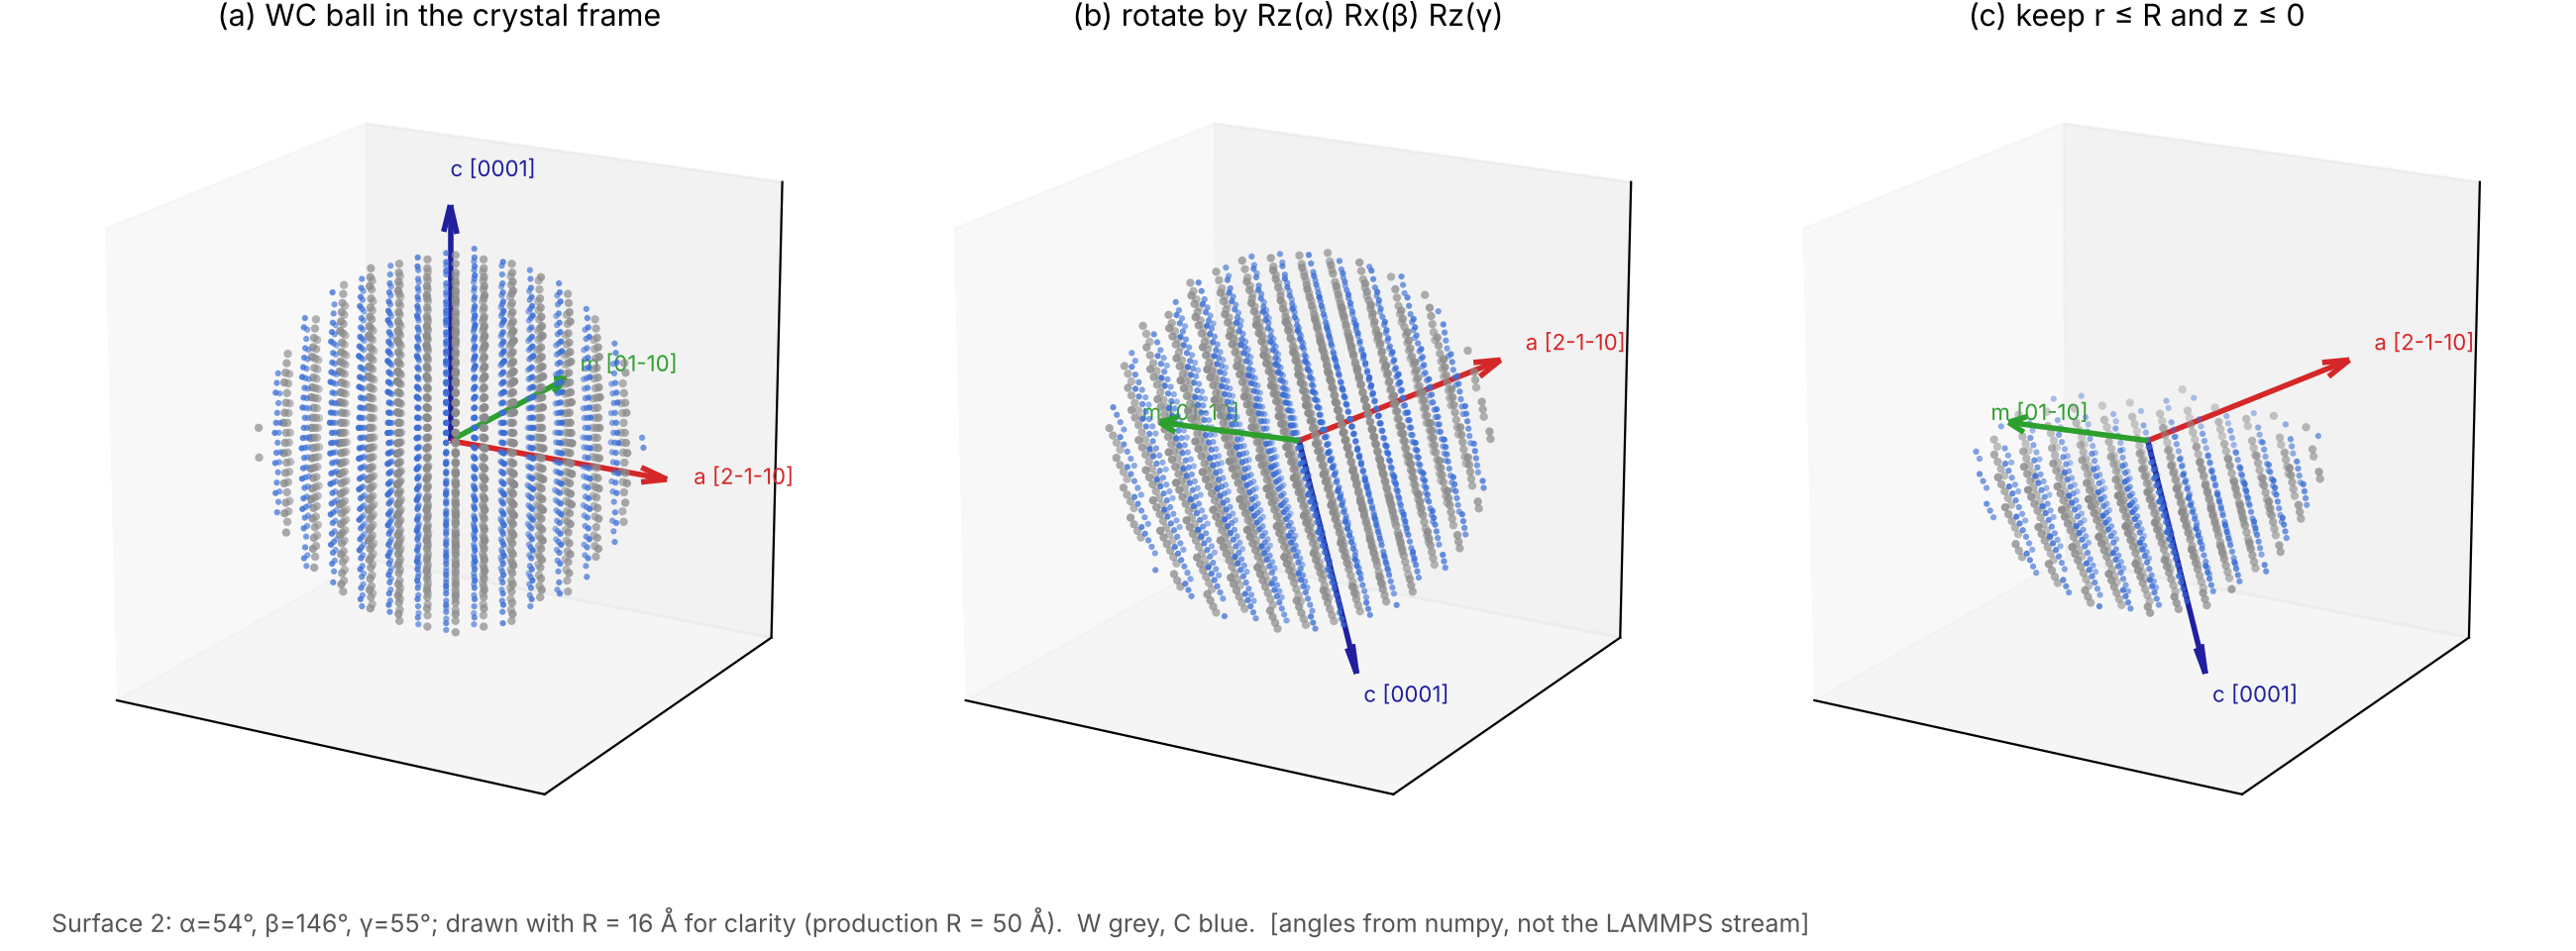

rand_crosssection_WC.png


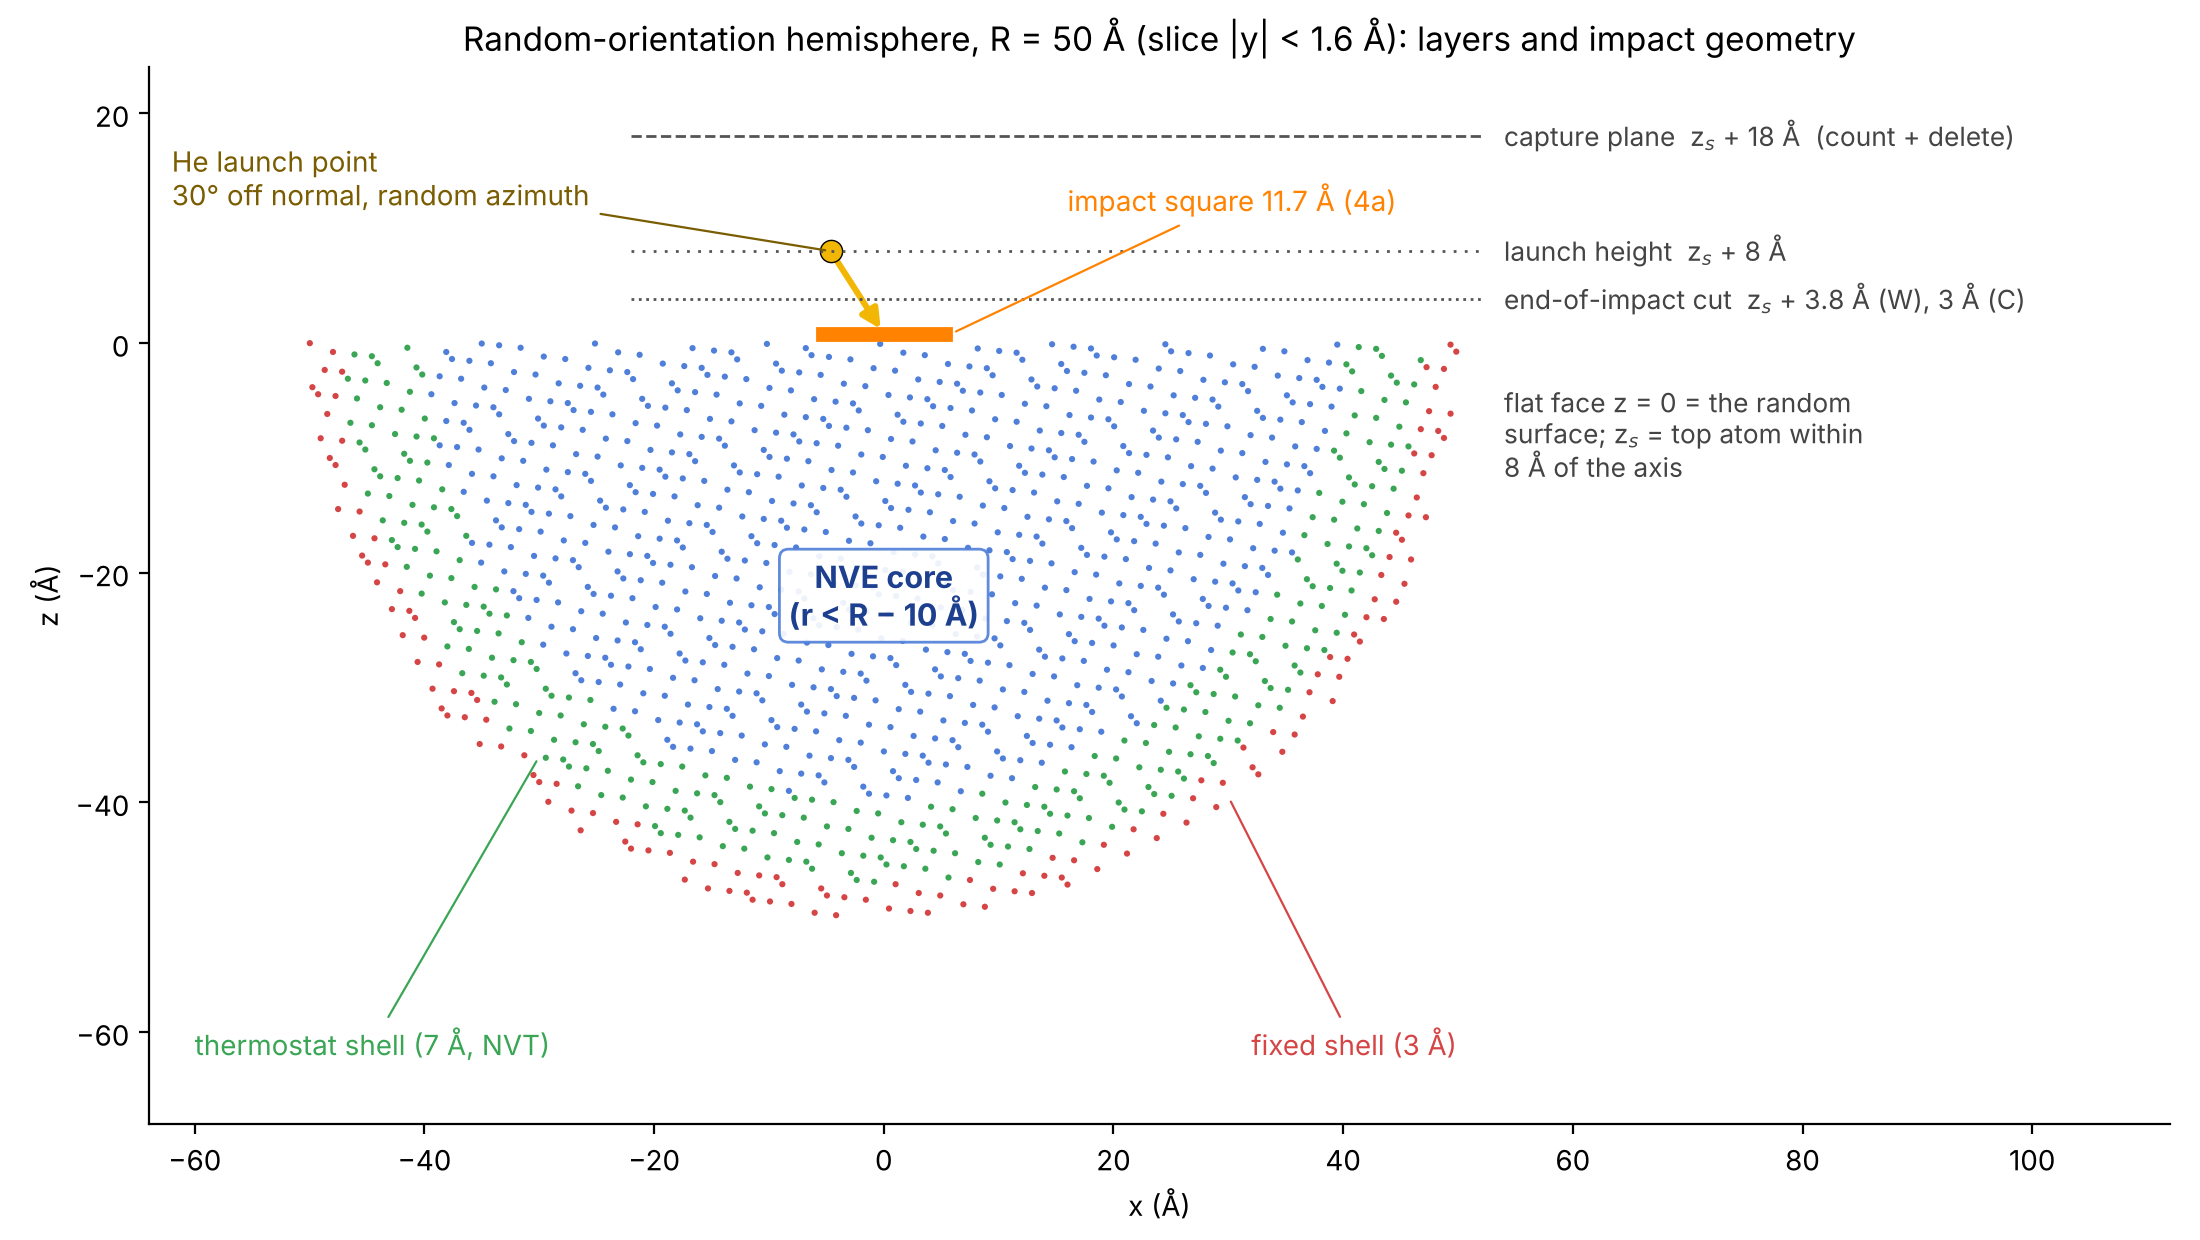

rand_orientations.png


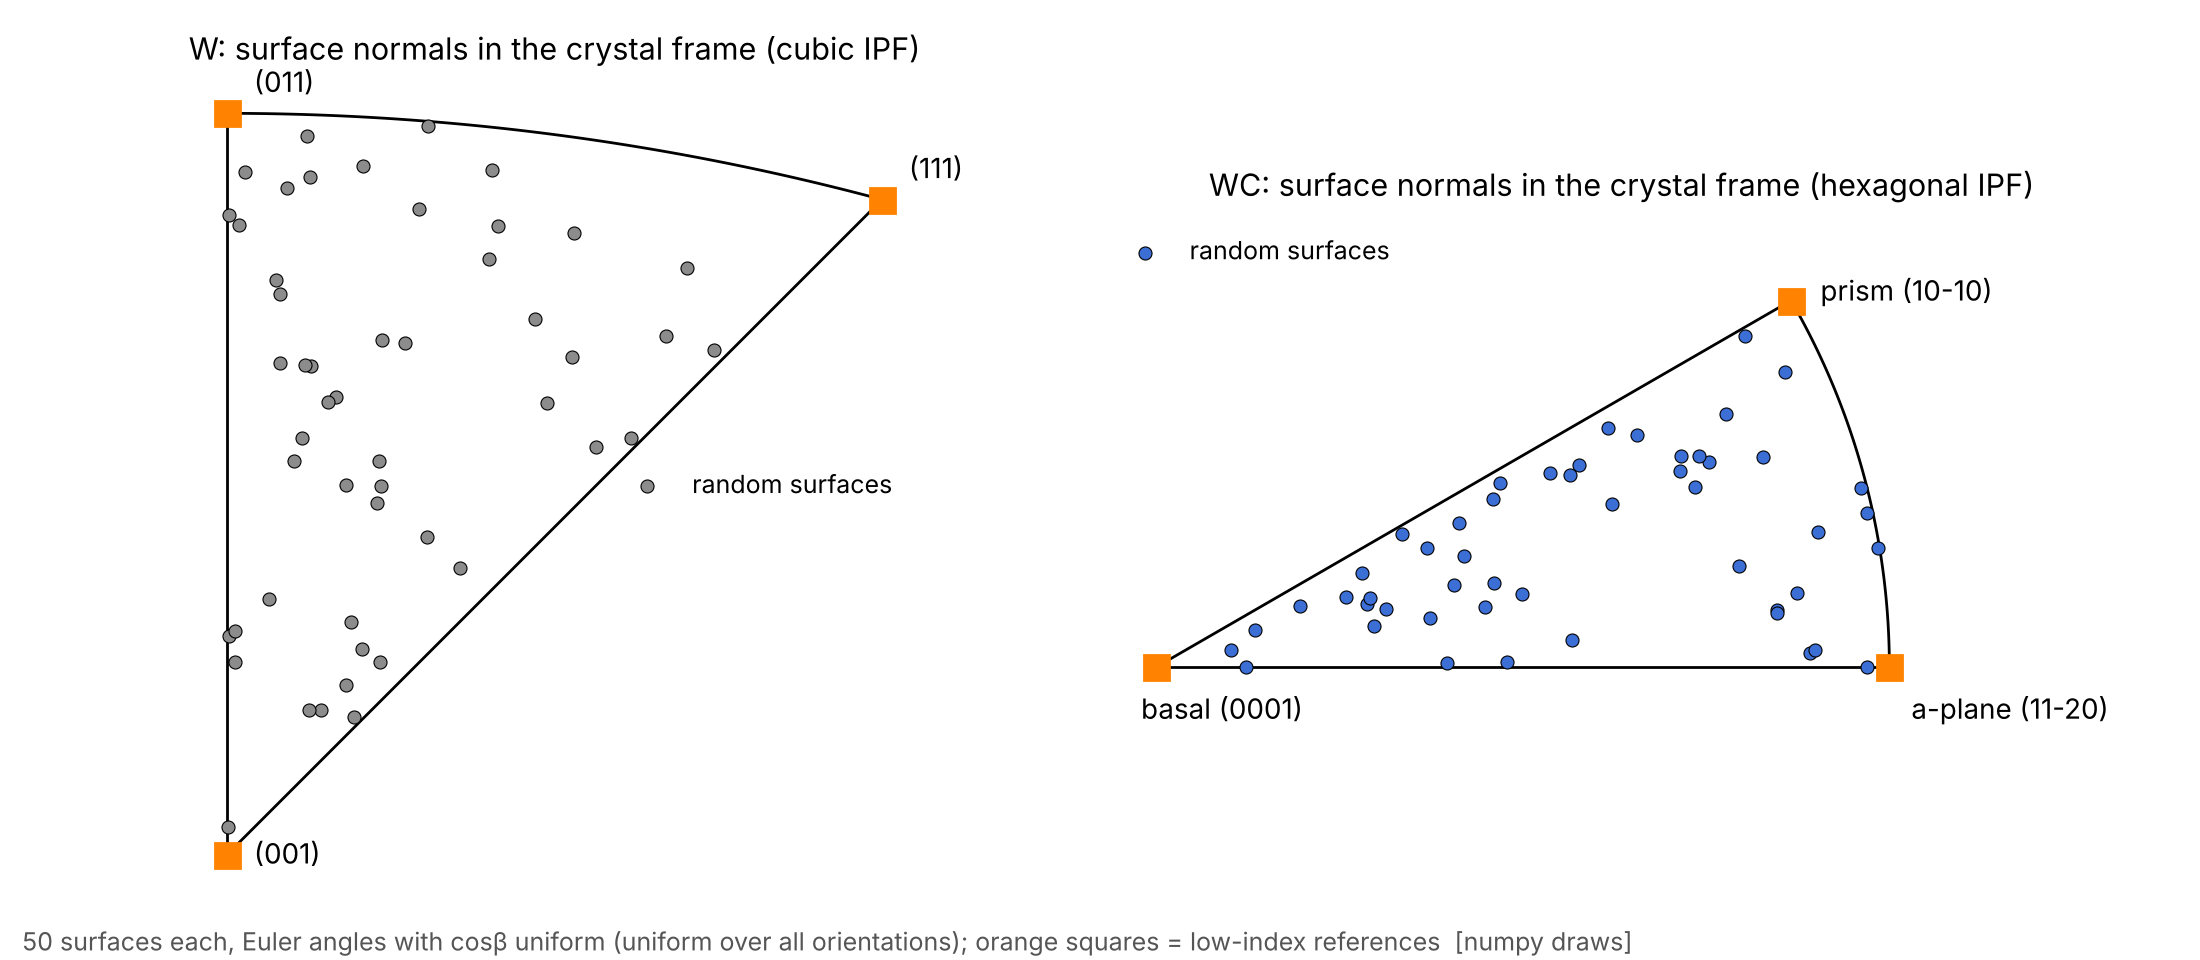

rand_example_surfaces.png


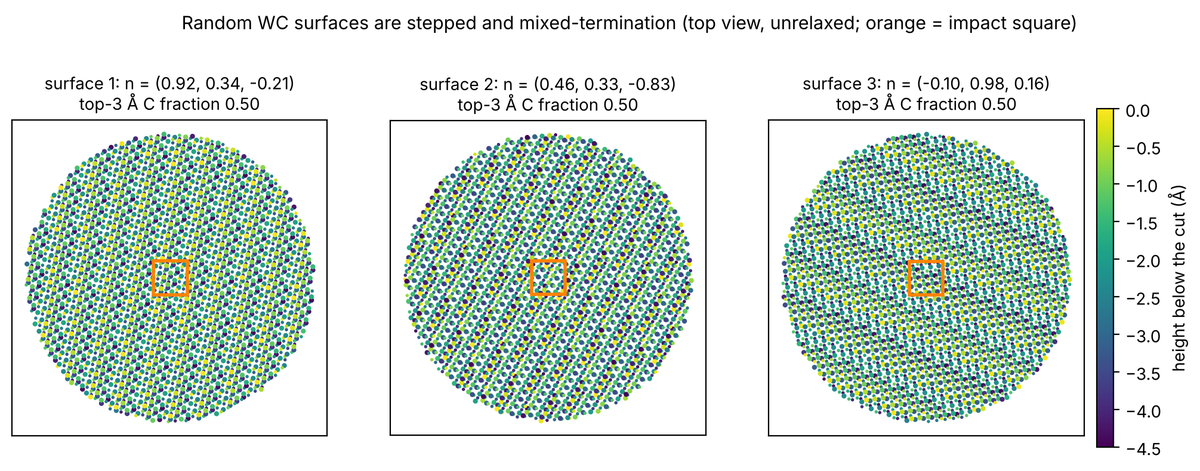

In [10]:
show(NB_OUT, ['rand_steps_WC.png', 'rand_crosssection_WC.png', 'rand_orientations.png', 'rand_example_surfaces.png'])